In [11]:

# 1. IMPORT LIBRARIES AND LOAD DATA


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Upload CSV files in Google Colab
from google.colab import files
uploaded = files.upload()

train_df = pd.read_csv("dataset_C_training.csv")
test_df = pd.read_csv("dataset_C_testing.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())


Saving dataset_C_testing.csv to dataset_C_testing (2).csv
Saving dataset_C_training.csv to dataset_C_training (2).csv
Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance           

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0


,0
employment_sector,2330
health_insurance,1908
income_poverty,748
rent_or_own,329
employment_status,238
marital_status,231
education,228
child_under_6_months,135
health_worker,132
opinion_covid_sick_from_vacc,90


Duplicates: 0

Vaccination distribution:
covid_vaccine
0    3202
1    1554
Name: count, dtype: int64


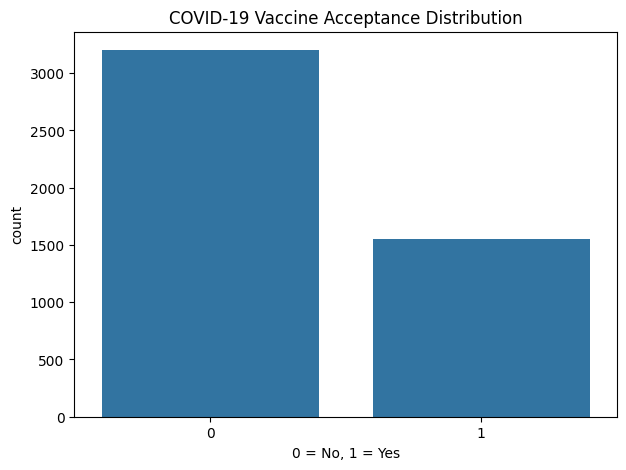

covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


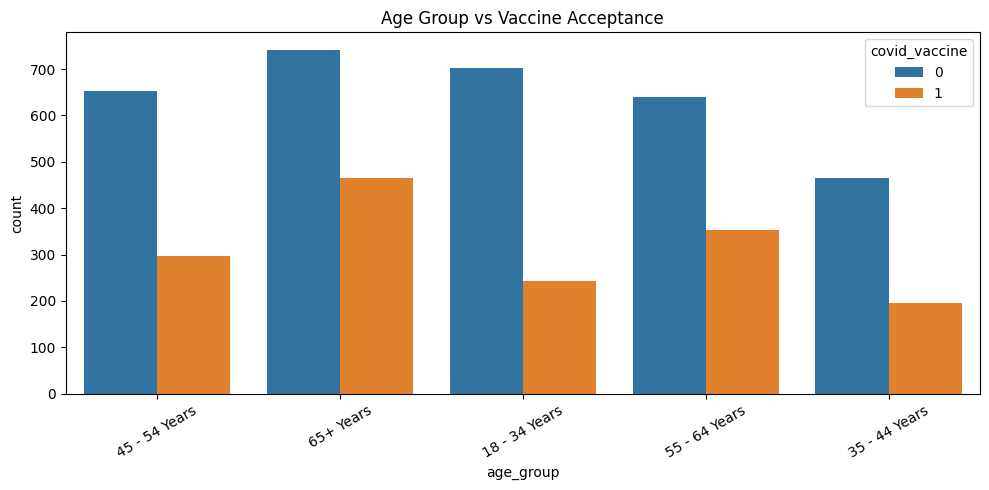

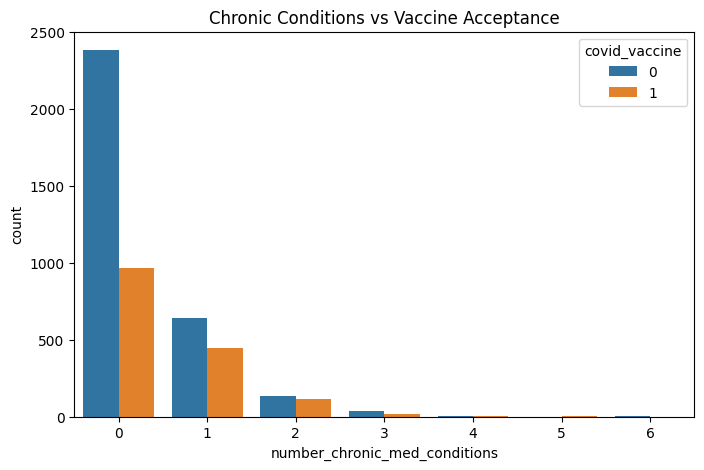

In [12]:

# 2. DATA EXPLORATION


print("Dataset information:")
train_df.info()

print("\nStatistical summary:")
display(train_df.describe(include="all").T)

# Missing values
missing = train_df.isnull().sum().sort_values(
    ascending=False
)

display(missing[missing > 0])

# Duplicate records
print("Duplicates:", train_df.duplicated().sum())

# Target distribution
print("\nVaccination distribution:")
print(train_df["covid_vaccine"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=train_df, x="covid_vaccine")
plt.title("COVID-19 Vaccine Acceptance Distribution")
plt.xlabel("0 = No, 1 = Yes")
plt.show()

# Target percentages
print(
    train_df["covid_vaccine"].value_counts(
        normalize=True
    ) * 100
)

# Explore age group and vaccine acceptance
plt.figure(figsize=(10, 5))
sns.countplot(
    data=train_df,
    x="age_group",
    hue="covid_vaccine"
)
plt.title("Age Group vs Vaccine Acceptance")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Chronic conditions
plt.figure(figsize=(8, 5))
sns.countplot(
    data=train_df,
    x="number_chronic_med_conditions",
    hue="covid_vaccine"
)
plt.title("Chronic Conditions vs Vaccine Acceptance")
plt.show()


In [13]:

# 3. DATA PREPROCESSING


# Remove duplicate rows
train_df = train_df.drop_duplicates().copy()

# Separate features and target
X = train_df.drop(
    columns=["covid_vaccine", "respondent_id"]
)

y = train_df["covid_vaccine"]

# Preserve test respondent IDs
test_ids = test_df["respondent_id"].copy()

X_test = test_df.drop(
    columns=["respondent_id"]
)

# Identify feature types
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Train validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


Training samples: 3804
Validation samples: 952


In [14]:

# 4. FIVE CLASSIFICATION MODELS


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_val)
    prob = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "F1": f1_score(y_val, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_val, prob)
    })

    trained_models[name] = pipeline

    print("\n", name)
    print(classification_report(
        y_val, pred, zero_division=0
    ))

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC_AUC", ascending=False
    ).round(4)
)



 Logistic Regression
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       641
           1       0.62      0.74      0.68       311

    accuracy                           0.77       952
   macro avg       0.74      0.76      0.75       952
weighted avg       0.78      0.77      0.77       952


 Decision Tree
              precision    recall  f1-score   support

           0       0.80      0.79      0.79       641
           1       0.58      0.60      0.59       311

    accuracy                           0.73       952
   macro avg       0.69      0.70      0.69       952
weighted avg       0.73      0.73      0.73       952


 Random Forest
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       641
           1       0.74      0.64      0.68       311

    accuracy                           0.81       952
   macro avg       0.79      0.76      0.77       952
weighted avg       0

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
4,Gradient Boosting,0.7994,0.7459,0.5852,0.6559,0.8334
2,Random Forest,0.8078,0.7388,0.6367,0.6839,0.8287
0,Logistic Regression,0.7700,0.6243,0.7428,0.6784,0.8282
3,Extra Trees,0.7815,0.6807,0.6238,0.6510,0.8265
1,Decision Tree,0.7269,0.5785,0.6045,0.5912,0.6932


In [15]:

# 5. FINANCIAL ASSUMPTIONS


# EXAMPLE VALUES ONLY - REPLACE WITH YOUR
# ASSIGNMENT'S ACTUAL TOWN-SPECIFIC COSTS.

VACCINE_COST = 20.0
COMPENSATION_COST = 20.0
HOSPITALISATION_COST = 10000.0

# Illustrative vaccine effectiveness against
# hospitalisation. Replace with a supported estimate.
VACCINE_EFFECTIVENESS = 0.50

# Illustrative baseline hospitalisation risks
# for unvaccinated individuals.
# Replace with estimates appropriate to your
# chosen disease, town and time period.

BASE_HOSPITAL_RISK = {
    "18 - 34 Years": 0.005,
    "35 - 44 Years": 0.010,
    "45 - 54 Years": 0.020,
    "55 - 64 Years": 0.040,
    "65+ Years": 0.080
}

# Illustrative multiplier for chronic conditions.
# Must be replaced with a justified estimate.
CHRONIC_RISK_MULTIPLIER = 1.5

print("Financial assumptions loaded.")


Financial assumptions loaded.


In [16]:

# 6. HOSPITALISATION RISK ESTIMATION


def estimate_hospital_risk(row, vaccinated=False):

    age = row["age_group"]

    # Baseline risk for the age category
    risk = BASE_HOSPITAL_RISK.get(age, np.nan)

    if pd.isna(risk):
        raise ValueError(
            f"Missing hospital risk estimate for age group: {age}"
        )

    # Chronic medical condition adjustment
    chronic = row["number_chronic_med_conditions"]

    if pd.isna(chronic):
        chronic = 0

    risk = risk * (
        CHRONIC_RISK_MULTIPLIER ** int(chronic)
    )

    # Apply vaccine effectiveness against
    # hospitalisation
    if vaccinated:
        risk = risk * (1 - VACCINE_EFFECTIVENESS)

    # Probability cannot exceed 100%
    return min(max(risk, 0), 1)


# Calculate risks for validation observations
val_risk_unvaccinated = X_val.apply(
    lambda row: estimate_hospital_risk(
        row, vaccinated=False
    ),
    axis=1
)

val_risk_vaccinated = X_val.apply(
    lambda row: estimate_hospital_risk(
        row, vaccinated=True
    ),
    axis=1
)

print("Hospitalisation risk estimation completed.")

display(pd.DataFrame({
    "Unvaccinated Risk": val_risk_unvaccinated,
    "Vaccinated Risk": val_risk_vaccinated
}).head())


Hospitalisation risk estimation completed.


,Unvaccinated Risk,Vaccinated Risk
145,0.005,0.0025
72,0.080,0.0400
2156,0.040,0.0200
3542,0.040,0.0200
2889,0.005,0.0025


In [17]:

# 7. COST OPTIMISATION FUNCTION


def calculate_cost_decisions(
    acceptance_probability,
    risk_unvaccinated,
    risk_vaccinated
):

    p = np.asarray(acceptance_probability)

    hu = np.asarray(risk_unvaccinated)
    hv = np.asarray(risk_vaccinated)

    # Option 1: Send vaccine
    # Vaccine is paid for whether used or wasted.
    cost_send = (
        VACCINE_COST
        + HOSPITALISATION_COST
        * (p * hv + (1 - p) * hu)
    )

    # Option 2: Do not send vaccine
    # Compensation is paid if person wants vaccine.
    cost_no_send = (
        p * COMPENSATION_COST
        + HOSPITALISATION_COST * hu
    )

    # Choose the action with minimum expected cost
    send_vaccine = cost_send < cost_no_send

    minimum_cost = np.minimum(
        cost_send,
        cost_no_send
    )

    return pd.DataFrame({
        "Acceptance_Probability": p,
        "Expected_Cost_Send": cost_send,
        "Expected_Cost_No_Send": cost_no_send,
        "Send_Vaccine": send_vaccine,
        "Minimum_Expected_Cost": minimum_cost
    })


# Calculate cost for each model on validation data

hospital_cost_results = []

for name, model in trained_models.items():

    probabilities = model.predict_proba(
        X_val
    )[:, 1]

    decisions = calculate_cost_decisions(
        probabilities,
        val_risk_unvaccinated,
        val_risk_vaccinated
    )

    total_cost = decisions[
        "Minimum_Expected_Cost"
    ].sum()

    hospital_cost_results.append({
        "Model": name,
        "Expected_Total_Cost": total_cost,
        "Expected_Average_Cost": total_cost / len(X_val),
        "People_Receiving_Vaccine": decisions[
            "Send_Vaccine"
        ].sum()
    })

cost_comparison = pd.DataFrame(
    hospital_cost_results
).sort_values(
    "Expected_Total_Cost"
)

print("COST OPTIMISATION RESULTS")

display(cost_comparison.round(2))

# Select lowest expected cost model
best_cost_model_name = cost_comparison.iloc[0]["Model"]

best_cost_model = trained_models[
    best_cost_model_name
]

print("Lowest expected cost model:",
      best_cost_model_name)


COST OPTIMISATION RESULTS


,Model,Expected_Total_Cost,Expected_Average_Cost,People_Receiving_Vaccine
0,Logistic Regression,350687.70,368.37,726
1,Decision Tree,361235.34,379.45,554
3,Extra Trees,366202.20,384.67,734
2,Random Forest,368901.63,387.50,717
4,Gradient Boosting,378611.23,397.70,643


Lowest expected cost model: Logistic Regression


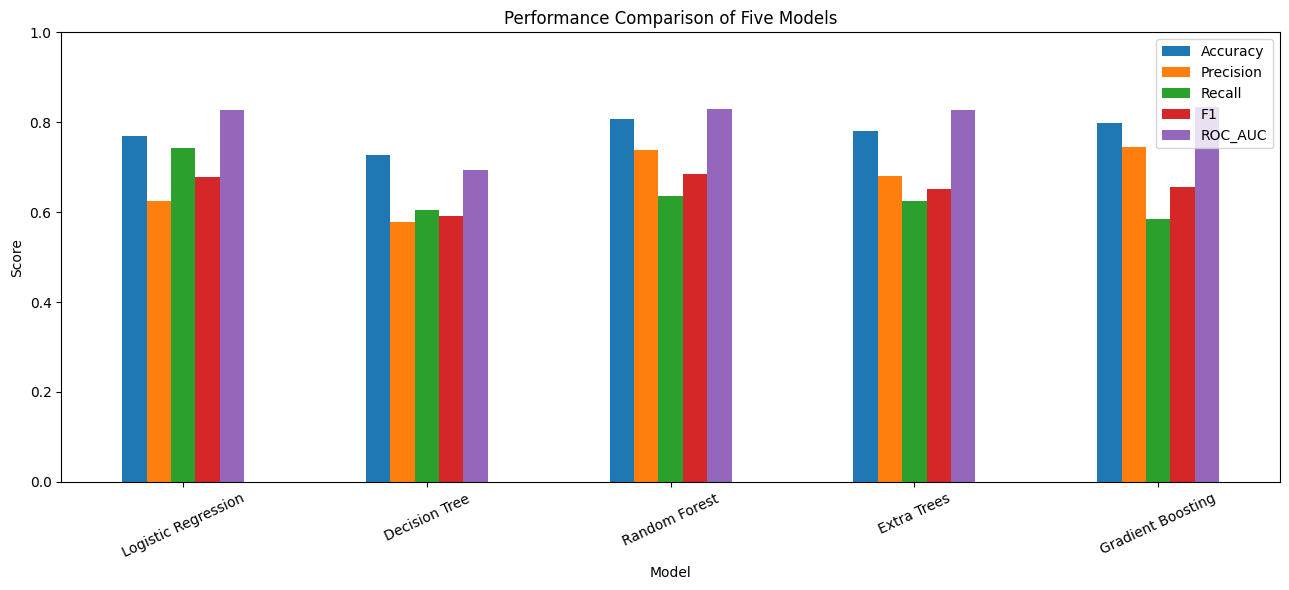

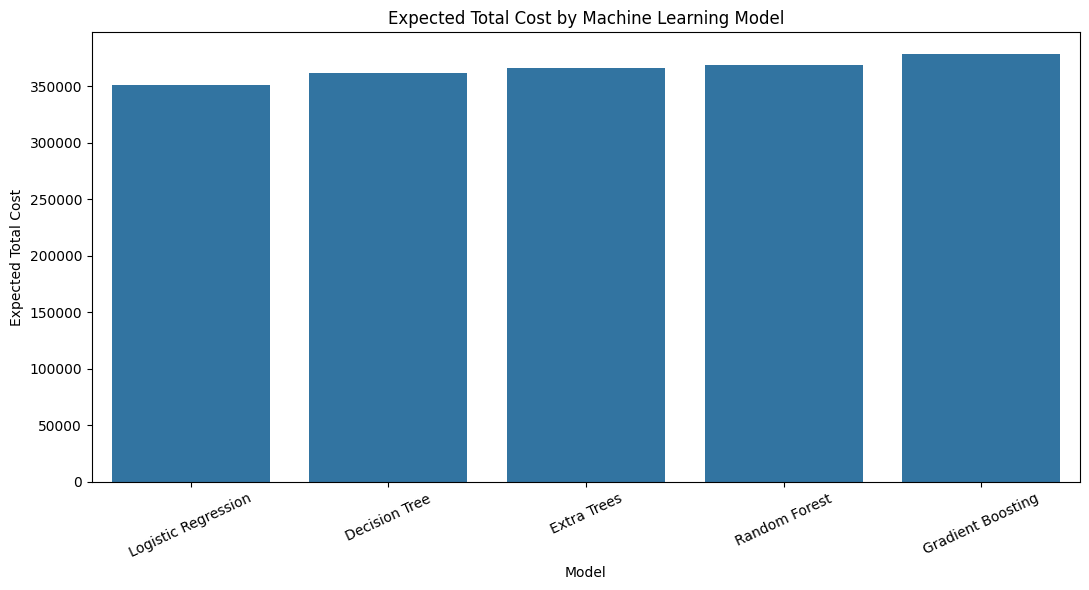

Selected model: Logistic Regression
                 precision    recall  f1-score   support

Does not accept       0.86      0.78      0.82       641
        Accepts       0.62      0.74      0.68       311

       accuracy                           0.77       952
      macro avg       0.74      0.76      0.75       952
   weighted avg       0.78      0.77      0.77       952

Confusion Matrix:
[[502 139]
 [ 80 231]]


In [18]:

# 8. PERFORMANCE AND COST ANALYSIS


# Model accuracy comparison
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Performance Comparison of Five Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Expected financial cost comparison
plt.figure(figsize=(11, 6))

sns.barplot(
    data=cost_comparison,
    x="Model",
    y="Expected_Total_Cost"
)

plt.title("Expected Total Cost by Machine Learning Model")
plt.ylabel("Expected Total Cost")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Best cost model classification performance
best_predictions = best_cost_model.predict(X_val)

print("Selected model:", best_cost_model_name)

print(classification_report(
    y_val,
    best_predictions,
    target_names=["Does not accept", "Accepts"],
    zero_division=0
))

print("Confusion Matrix:")

print(confusion_matrix(
    y_val,
    best_predictions
))


In [19]:

# 9. FINAL TESTING AND SUBMISSION


# Train selected model on complete training dataset
best_cost_model.fit(X, y)

# Predict acceptance probabilities
test_acceptance_prob = best_cost_model.predict_proba(
    X_test
)[:, 1]

# Predict acceptance class
test_acceptance = (
    test_acceptance_prob >= 0.50
).astype(int)

# Estimate hospitalisation risks
test_risk_unvaccinated = X_test.apply(
    lambda row: estimate_hospital_risk(
        row, vaccinated=False
    ),
    axis=1
)

test_risk_vaccinated = X_test.apply(
    lambda row: estimate_hospital_risk(
        row, vaccinated=True
    ),
    axis=1
)

# Calculate optimal cost decisions
test_cost_results = calculate_cost_decisions(
    test_acceptance_prob,
    test_risk_unvaccinated,
    test_risk_vaccinated
)

# Standard acceptance prediction submission
submission = pd.DataFrame({
    "respondent_id": test_ids,
    "covid_vaccine": test_acceptance
})

submission.to_csv(
    "submission.csv",
    index=False
)

# Detailed financial decision output
detailed_submission = pd.DataFrame({
    "respondent_id": test_ids,
    "predicted_acceptance": test_acceptance,
    "acceptance_probability": test_acceptance_prob,
    "hospital_risk_unvaccinated": test_risk_unvaccinated,
    "hospital_risk_vaccinated": test_risk_vaccinated,
    "send_vaccine": test_cost_results["Send_Vaccine"],
    "expected_cost_send": test_cost_results["Expected_Cost_Send"],
    "expected_cost_no_send": test_cost_results["Expected_Cost_No_Send"],
    "minimum_expected_cost": test_cost_results["Minimum_Expected_Cost"]
})

detailed_submission.to_csv(
    "cost_optimisation_results.csv",
    index=False
)

print("Submission files created.")

print("\nPredicted acceptance distribution:")
print(submission["covid_vaccine"].value_counts())

print("\nNumber of vaccines to send:")
print(
    detailed_submission["send_vaccine"].sum()
)

print("\nExpected total financial cost:")
print(
    detailed_submission[
        "minimum_expected_cost"
    ].sum()
)

display(detailed_submission.head())

# Download both files
from google.colab import files

files.download("submission.csv")
files.download("cost_optimisation_results.csv")


Submission files created.

Predicted acceptance distribution:
covid_vaccine
0    2856
1    1893
Name: count, dtype: int64

Number of vaccines to send:
3674

Expected total financial cost:
1708831.2340467751


,respondent_id,predicted_acceptance,acceptance_probability,hospital_risk_unvaccinated,hospital_risk_vaccinated,send_vaccine,expected_cost_send,expected_cost_no_send,minimum_expected_cost
0,4757,0,0.323851,0.08,0.040,True,690.459783,806.477011,690.459783
1,4758,0,0.334092,0.08,0.040,True,686.363375,806.681831,686.363375
2,4759,0,0.398240,0.08,0.040,True,660.703953,807.964802,660.703953
3,4760,0,0.293257,0.06,0.030,True,532.022894,605.865140,532.022894
4,4761,0,0.136454,0.01,0.005,False,113.177309,102.729076,102.729076


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>